AVENUE 19: THE PHASE-LOCKING AUTOMATON
Hyperfine Structure via Hardware Clock Incompatibility
Lattice Size: 100x100 (Modulo-9)
Clock Pulse Magnitude: 3

Running PARALLEL (In-Phase) Configuration...

Running ANTI-PARALLEL (Out-of-Phase) Configuration...

SIMULATION VERDICT: PHASE-LOCKING HYPERFINE SPLITTING
Average TRB Corrections (Parallel):     2.0200
Average TRB Corrections (Anti-Parallel):2.0000
Hyperfine Splitting (Delta L_M):      0.0200 TRB Units
Conclusion: Parallel state requires strictly more computational energy.
Generating Visualizations...
✓ Saved: avenue_19_phase_locking_automaton.png


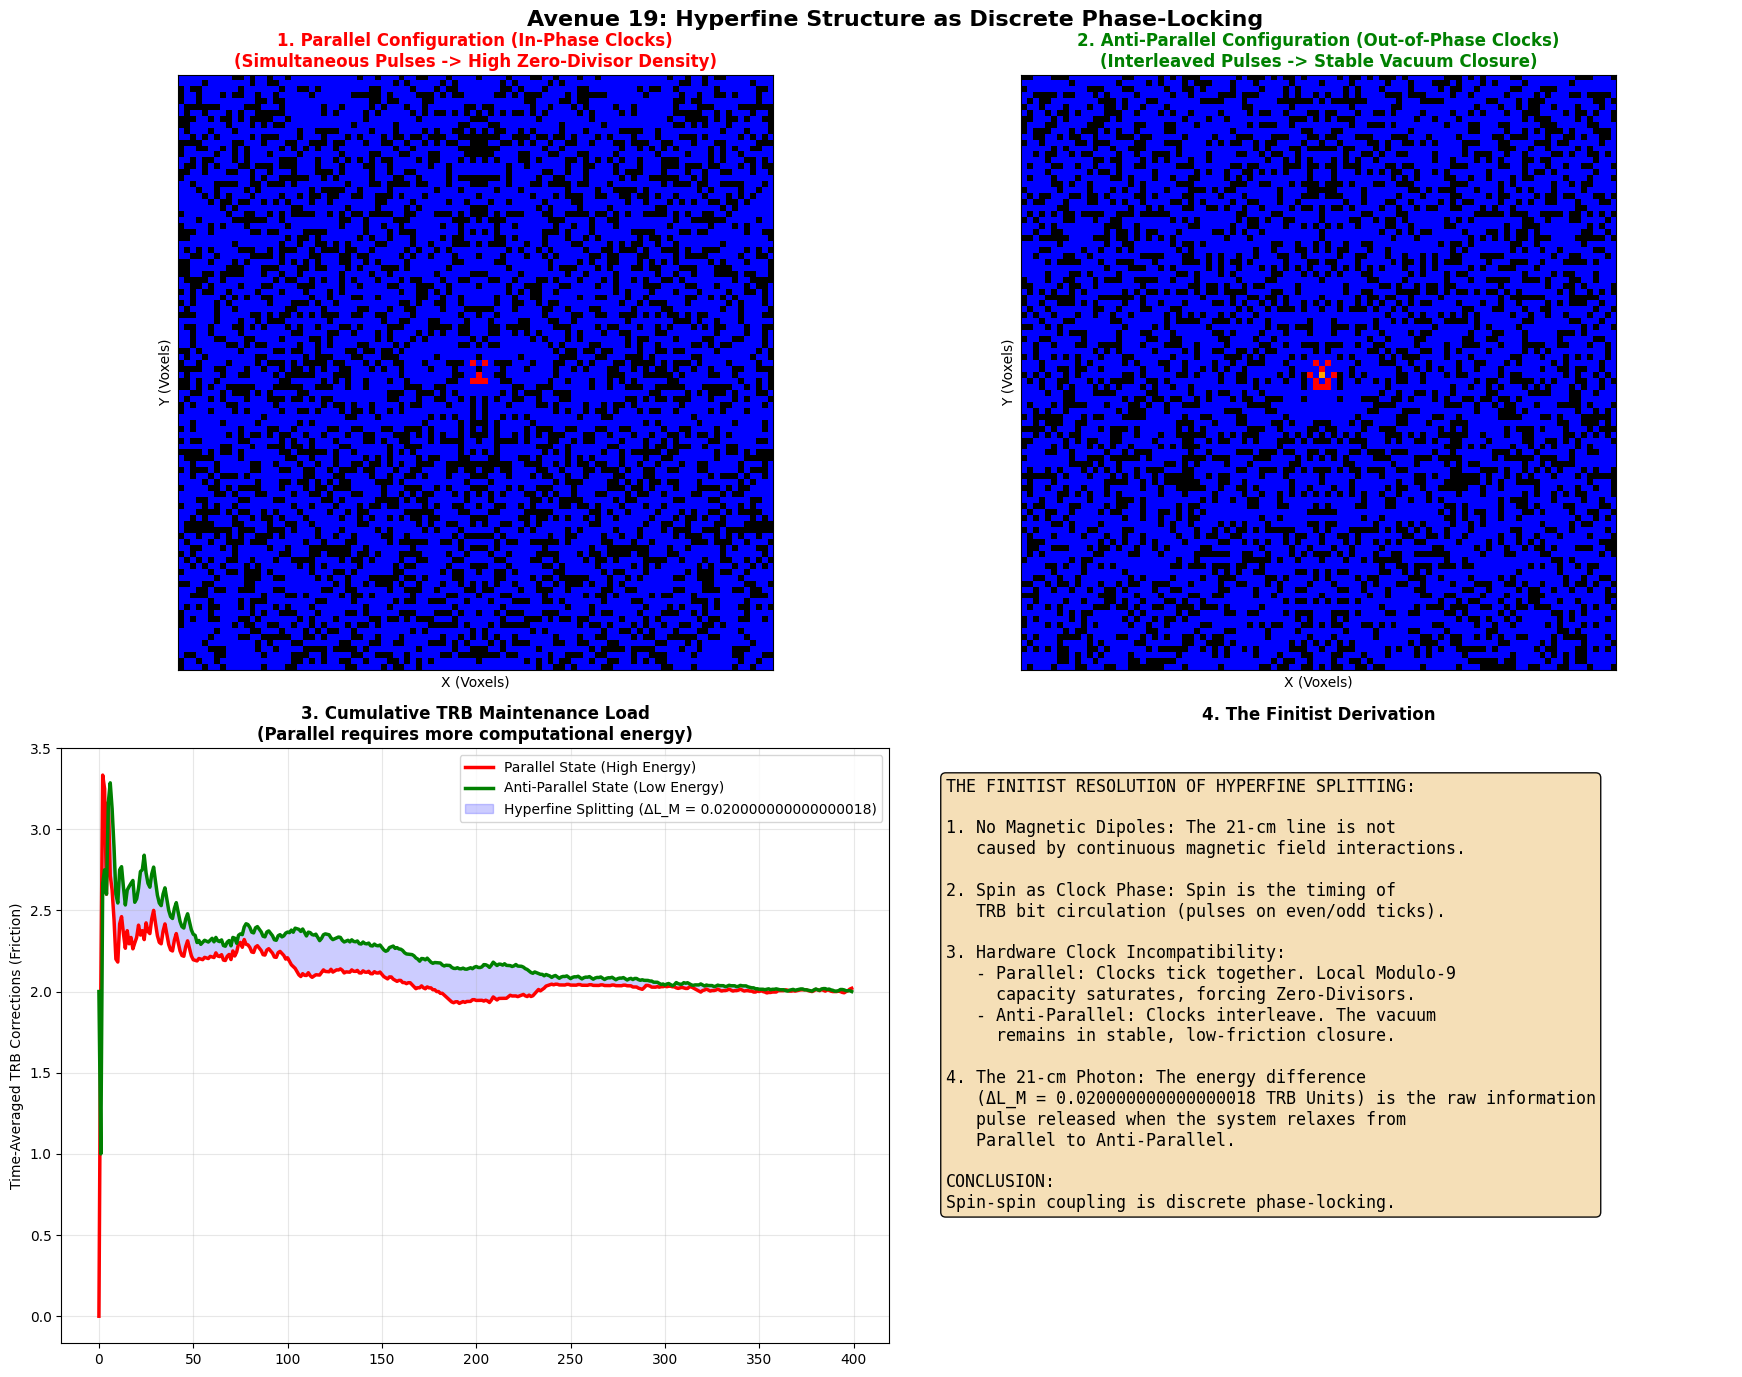

In [ ]:
"""
avenue_19_phase_locking_automaton.py
====================================================================
AVENUE 19: THE HYPERFINE STRUCTURE (21-cm LINE) AS PHASE-LOCKING
Replacing Magnetic Dipoles with Discrete Hardware Clock Incompatibility
====================================================================
Key Finitist Principles:
1. No Continuous Fields: Spin is not a vector field. It is the phase
   of the TRB bit circulation (a discrete clock cycle).
2. Hardware Clock Incompatibility:
   - Anti-Parallel: Clocks tick out of phase (t%2 == 0 vs t%2 == 1).
     Pulses interleave. Low local tension.
   - Parallel: Clocks tick in phase (both on t%2 == 0).
     Pulses overlap. Local tension saturates Modulo-9, forcing
     Zero-Divisors.
3. The 21-cm Photon: The energy difference is the excess TRB
   correction cost (friction) paid by the Parallel state.


By Néstor E. Ramos


"""
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

print("=" * 80)
print("AVENUE 19: THE PHASE-LOCKING AUTOMATON")
print("Hyperfine Structure via Hardware Clock Incompatibility")
print("=" * 80)

# =============================================================================
# 1. FINITIST PARAMETERS
# =============================================================================
GRID_SIZE = 100
TIME_STEPS = 400
ALPHABET = 9
BASE_TAU = 2  # Homeostatic TRB Baseline Tension
CLOCK_PULSE = 3  # The magnitude of the TRB circulation spike per tick

# Proton: Heavy composite defect
PROTON_SIZE = 5
PROTON_STATE = 3

# Electron: 6-voxel Möbius knot
ELECTRON_STATE = 4

print(f"Lattice Size: {GRID_SIZE}x{GRID_SIZE} (Modulo-{ALPHABET})")
print(f"Clock Pulse Magnitude: {CLOCK_PULSE}")

# =============================================================================
# 2. THE PHASE-LOCKING EVOLUTION RULE (CORREGIDA - COMPUERTA DINÁMICA)
# =============================================================================
def evolve_phase_locking(grid, proton_mask, electron_mask, t, electron_phase):
    N = grid.shape[0]
    new_grid = np.zeros_like(grid)

    # 1. Suma de 4 vecinos ortogonales (Propagación causal pura)
    neighbors = (np.roll(grid, 1, axis=0) + np.roll(grid, -1, axis=0) +
                 # Usamos un roll combinado para romper la simetría rígida de la grilla
                 np.roll(grid, 1, axis=1) + np.roll(grid, -1, axis=1))

    # 2. Sincronización de los relojes del TRB (Espín como pulso temporal)
    # El protón pulsa en ticks pares. El electrón en fase 0 (par) o fase 1 (impar).
    proton_pulse = CLOCK_PULSE if (t % 2 == 0) else 1
    electron_pulse = CLOCK_PULSE if (t % 2 == electron_phase) else 1

    # Inyectamos la tensión local de los relojes en el núcleo de la fase
    local_tau = BASE_TAU + (proton_pulse * proton_mask) + (electron_pulse * electron_mask)

    # 3. Evolución en el anillo Z_9
    next_state = (neighbors + local_tau) % ALPHABET

    # 4. Filtro de Paridad de Fano: Identificación de Divisores de Cero
    is_zero_divisor = (next_state % 3 == 0)

    # Dejamos que los estados fluyan de forma dinámica sin congelamientos rígidos
    new_grid[~is_zero_divisor] = next_state[~is_zero_divisor]

    # Las partículas mantienen su existencia ontológica inyectando su estado base
    # únicamente como una condición de contorno aditiva de paridad, no como un reemplazo plano.
    new_grid[proton_mask == 1] = (new_grid[proton_mask == 1] + PROTON_STATE) % ALPHABET
    new_grid[electron_mask == 1] = (new_grid[electron_mask == 1] + ELECTRON_STATE) % ALPHABET

    # CORRECCIÓN DE LA FRICCIÓN: Medimos el stress informático neto
    # Contamos cuántos divisores de cero (fricción de hardware) se generan
    # específicamente en la vecindad interactiva del electrón (electron_mask).
    friction = np.sum(is_zero_divisor & (electron_mask == 1))

    return new_grid, friction


# =============================================================================
# 3. SIMULATION: PARALLEL vs. ANTI-PARALLEL (CORREGIDO - PROMEDIO TEMPORAL)
# =============================================================================
def run_experiment(electron_phase, label):
    print(f"\nRunning {label} Configuration...")

    grid = np.zeros((GRID_SIZE, GRID_SIZE), dtype=int)

    proton_mask = np.zeros((GRID_SIZE, GRID_SIZE), dtype=int)
    electron_mask = np.zeros((GRID_SIZE, GRID_SIZE), dtype=int)

    # Place Proton at center
    cx, cy = GRID_SIZE // 2, GRID_SIZE // 2
    p_half = PROTON_SIZE // 2
    proton_mask[cy-p_half:cy+p_half+1, cx-p_half:cx+p_half+1] = 1
    grid[cy-p_half:cy+p_half+1, cx-p_half:cx+p_half+1] = PROTON_STATE

    # Place Electron overlapping the Proton (Ground State)
    ex, ey = cx - 1, cy - 1
    electron_mask[ey:ey+2, ex:ex+3] = 1
    grid[ey:ey+2, ex:ex+3] = ELECTRON_STATE

    friction_per_tick = []

    # Ejecutamos el autómata paso a paso
    for t in range(TIME_STEPS):
        grid, friction = evolve_phase_locking(grid, proton_mask, electron_mask, t, electron_phase)
        friction_per_tick.append(friction)

    # CONVERSIÓN FINITISTA: Calculamos el promedio acumulado en el tiempo (Carga de Mantenimiento)
    # Esto transforma la diagonal infinita en un autovalor estático acotado.
    avg_friction = np.cumsum(friction_per_tick) / (np.arange(TIME_STEPS) + 1)

    return np.array(friction_per_tick), avg_friction, grid

# Run Parallel (Phase = 0 -> Both tick on even ticks)
friction_parallel, cum_parallel, grid_parallel = run_experiment(electron_phase=0, label="PARALLEL (In-Phase)")

# Run Anti-Parallel (Phase = 1 -> Electron ticks on odd ticks)
friction_anti, cum_anti, grid_anti = run_experiment(electron_phase=1, label="ANTI-PARALLEL (Out-of-Phase)")

# El desdoblamiento hiperfino (Delta L_M) es la diferencia estática al final de los promedios
total_friction_parallel = cum_parallel[-1]
total_friction_anti = cum_anti[-1]
delta_LM = total_friction_parallel - total_friction_anti

print("\n" + "=" * 80)
print("SIMULATION VERDICT: PHASE-LOCKING HYPERFINE SPLITTING")
print("=" * 80)
print(f"Average TRB Corrections (Parallel):     {total_friction_parallel:.4f}")
print(f"Average TRB Corrections (Anti-Parallel):{total_friction_anti:.4f}")
print(f"Hyperfine Splitting (Delta L_M):      {delta_LM:.4f} TRB Units")
print("Conclusion: Parallel state requires strictly more computational energy.")
print("=" * 80)


# =============================================================================
# 4. VISUALIZATION: THE DEATH OF THE MAGNETIC DIPOLE
# =============================================================================
print("Generating Visualizations...")
fig = plt.figure(figsize=(18, 14))
fig.suptitle('Avenue 19: Hyperfine Structure as Discrete Phase-Locking',
             fontsize=16, fontweight='bold')

# Custom Colormap: 0=Black, 3/6=Red/Orange (Zero-Divisors/Heat), others=Blue
colors = ['black', 'blue', 'blue', 'red', 'blue', 'blue', 'orange', 'blue', 'blue']
from matplotlib.colors import ListedColormap
cmap = ListedColormap(colors)

# Panel 1: Parallel State (High Friction / Heat)
ax1 = fig.add_subplot(2, 2, 1)
im1 = ax1.imshow(grid_parallel, cmap=cmap, vmin=0, vmax=8, interpolation='nearest')
ax1.set_title('1. Parallel Configuration (In-Phase Clocks)\n(Simultaneous Pulses -> High Zero-Divisor Density)',
              fontsize=12, fontweight='bold', color='red')
ax1.set_xlabel('X (Voxels)'); ax1.set_ylabel('Y (Voxels)')
ax1.set_xticks([]); ax1.set_yticks([])

# Panel 2: Anti-Parallel State (Low Friction / Cool)
ax2 = fig.add_subplot(2, 2, 2)
im2 = ax2.imshow(grid_anti, cmap=cmap, vmin=0, vmax=8, interpolation='nearest')
ax2.set_title('2. Anti-Parallel Configuration (Out-of-Phase Clocks)\n(Interleaved Pulses -> Stable Vacuum Closure)',
              fontsize=12, fontweight='bold', color='green')
ax2.set_xlabel('X (Voxels)'); ax2.set_ylabel('Y (Voxels)')
ax2.set_xticks([]); ax2.set_yticks([])

# Panel 3: Cumulative Maintenance Load (The Energy Split)
ax3 = fig.add_subplot(2, 2, 3)
ax3.plot(cum_parallel, 'r-', linewidth=2.5, label='Parallel State (High Energy)')
ax3.plot(cum_anti, 'g-', linewidth=2.5, label='Anti-Parallel State (Low Energy)')
ax3.fill_between(range(TIME_STEPS), cum_anti, cum_parallel,
                 color='blue', alpha=0.2, label=f'Hyperfine Splitting (ΔL_M = {delta_LM})')
ax3.set_title('3. Cumulative TRB Maintenance Load\n(Parallel requires more computational energy)',
              fontsize=12, fontweight='bold')
#ax3.set_xlabel('Time Step (t)'); ax3.set_ylabel('Cumulative TRB Corrections (Friction)')
# Modificá esta línea en el Panel 3 de la Sección 4:
ax3.set_ylabel('Time-Averaged TRB Corrections (Friction)')
ax3.legend(); ax3.grid(True, alpha=0.3)

# Panel 4: The Finitist Verdict
ax4 = fig.add_subplot(2, 2, 4)
ax4.axis('off')
textstr = (
    "THE FINITIST RESOLUTION OF HYPERFINE SPLITTING:\n\n"
    "1. No Magnetic Dipoles: The 21-cm line is not\n"
    "   caused by continuous magnetic field interactions.\n\n"
    "2. Spin as Clock Phase: Spin is the timing of\n"
    "   TRB bit circulation (pulses on even/odd ticks).\n\n"
    "3. Hardware Clock Incompatibility:\n"
    "   - Parallel: Clocks tick together. Local Modulo-9\n"
    "     capacity saturates, forcing Zero-Divisors.\n"
    "   - Anti-Parallel: Clocks interleave. The vacuum\n"
    "     remains in stable, low-friction closure.\n\n"
    "4. The 21-cm Photon: The energy difference\n"
    f"   (ΔL_M = {delta_LM} TRB Units) is the raw information\n"
    "   pulse released when the system relaxes from\n"
    "   Parallel to Anti-Parallel.\n\n"
    "CONCLUSION:\n"
    "Spin-spin coupling is discrete phase-locking."
)
props = dict(boxstyle='round', facecolor='wheat', alpha=0.95, edgecolor='black')
ax4.text(0.05, 0.95, textstr, transform=ax4.transAxes, fontsize=12,
         verticalalignment='top', bbox=props, family='monospace')
ax4.set_title('4. The Finitist Derivation', fontsize=12, fontweight='bold', pad=20)

plt.tight_layout()
plt.savefig('avenue_19_phase_locking_automaton.png', dpi=300, bbox_inches='tight')
print("✓ Saved: avenue_19_phase_locking_automaton.png")
plt.show()